# CT Filter and Noise Comparison

## Objective

Evaluate how reconstruction filters affect CT image quality at different projection noise levels.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.transform import iradon, radon

from medimaging.quality.psnr import calculate_psnr
from medimaging.quality.ssim import calculate_ssim
from medimaging.simulation.phantom import create_shepp_logan

## Paso 2. Preparar el phantom y el sinograma

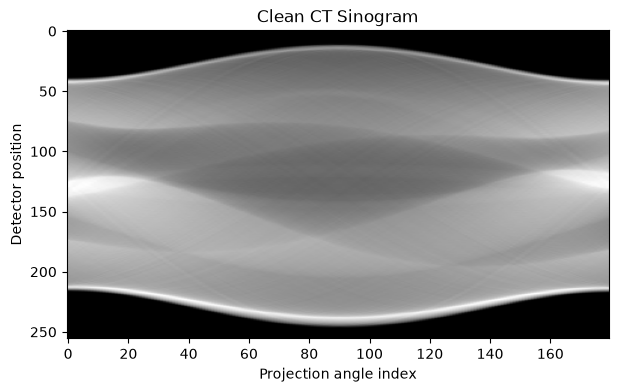

In [2]:
phantom = create_shepp_logan(256)

n_projections = 180
theta = np.linspace(
    0.0,
    180.0,
    n_projections,
    endpoint=False,
)

sinogram_clean = radon(
    phantom,
    theta=theta,
    circle=True,
)

plt.figure(figsize=(7, 4))
plt.imshow(sinogram_clean, cmap="gray", aspect="auto")
plt.title("Clean CT Sinogram")
plt.xlabel("Projection angle index")
plt.ylabel("Detector position")
plt.show()

## Paso 3. Definir los filtros y los niveles de ruido

In [3]:
filter_names = [
    "ramp",
    "shepp-logan",
    "cosine",
    "hann",
    "hamming",
]

noise_levels = [0.0, 0.01, 0.03, 0.05, 0.1]

rng = np.random.default_rng(42)

## Paso 4. Ejecutar el experimento completo

In [4]:
results = []

for noise_std in noise_levels:
    noise = rng.normal(
        loc=0.0,
        scale=noise_std,
        size=sinogram_clean.shape,
    )

    sinogram_noisy = sinogram_clean + noise

    for filter_name in filter_names:
        reconstruction = iradon(
            sinogram_noisy,
            theta=theta,
            filter_name=filter_name,
            circle=True,
        )

        psnr = calculate_psnr(phantom, reconstruction)

        ssim = calculate_ssim(phantom, reconstruction)

        results.append(
            {
                "noise_std": noise_std,
                "filter": filter_name,
                "psnr": psnr,
                "ssim": ssim,
            }
        )

results_df = pd.DataFrame(results)

results_df

,noise_std,filter,psnr,ssim
0,0.00,ramp,30.774608,0.921829
1,0.00,shepp-logan,29.879193,0.941527
2,0.00,cosine,28.179924,0.960527
3,0.00,hann,26.846327,0.957948
4,0.00,hamming,27.134424,0.958476
5,0.01,ramp,30.774079,0.921681
6,0.01,shepp-logan,29.879059,0.941420
7,0.01,cosine,28.180046,0.960473
8,0.01,hann,26.846513,0.957918
9,0.01,hamming,27.134610,0.958442


## Paso 5. Comparar el PSNR 

In [5]:
psnr_table = results_df.pivot(
    index="noise_std",
    columns="filter",
    values="psnr",
)

psnr_table

filter,cosine,hamming,hann,ramp,shepp-logan
noise_std,,,,,
0.00,28.179924,27.134424,26.846327,30.774608,29.879193
0.01,28.180046,27.134610,26.846513,30.774079,29.879059
0.03,28.177852,27.133085,26.845204,30.764262,29.873124
0.05,28.176931,27.133277,26.845651,30.750908,29.866297
0.10,28.170778,27.130634,26.843434,30.696123,29.839337


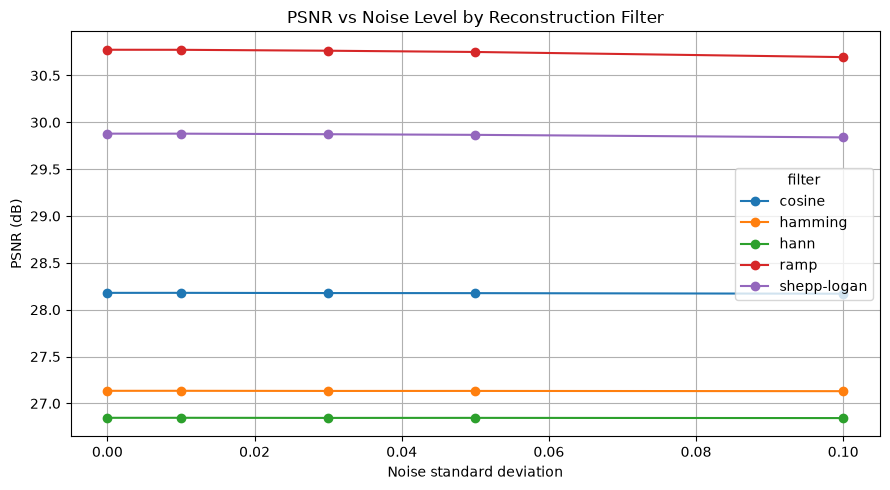

In [6]:
psnr_table.plot(
    marker="o",
    figsize=(9, 5),
)

plt.title("PSNR vs Noise Level by Reconstruction Filter")
plt.xlabel("Noise standard deviation")
plt.ylabel("PSNR (dB)")
plt.grid(True)
plt.tight_layout()
plt.show()

## Paso 6. Comparar el SSIM

In [7]:
ssim_table = results_df.pivot(
    index="noise_std",
    columns="filter",
    values="ssim",
)

ssim_table

filter,cosine,hamming,hann,ramp,shepp-logan
noise_std,,,,,
0.00,0.960527,0.958476,0.957948,0.921829,0.941527
0.01,0.960473,0.958442,0.957918,0.921681,0.941420
0.03,0.960103,0.958196,0.957701,0.920666,0.940679
0.05,0.959419,0.957753,0.957311,0.918838,0.939332
0.10,0.956320,0.955745,0.955562,0.909745,0.932771


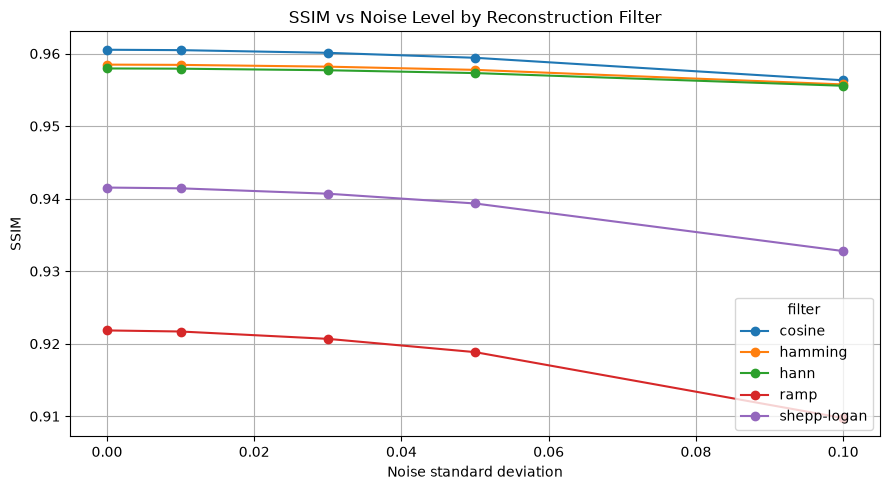

In [8]:
ssim_table.plot(
    marker="o",
    figsize=(9, 5),
)

plt.title("SSIM vs Noise Level by Reconstruction Filter")
plt.xlabel("Noise standard deviation")
plt.ylabel("SSIM")
plt.grid(True)
plt.tight_layout()
plt.show()

## Paso 7. Identificar el mejor filtro para cada nivel de ruido

In [9]:
best_psnr = results_df.loc[
    results_df.groupby("noise_std")["psnr"].idxmax(),
    ["noise_std", "filter", "psnr", "ssim"],
].reset_index(drop=True)

best_ssim = results_df.loc[
    results_df.groupby("noise_std")["ssim"].idxmax(),
    ["noise_std", "filter", "psnr", "ssim"],
].reset_index(drop=True)

print("Best filter by PSNR:")
display(best_psnr)

print("Best filter by SSIM:")
display(best_ssim)

Best filter by PSNR:


,noise_std,filter,psnr,ssim
0,0.00,ramp,30.774608,0.921829
1,0.01,ramp,30.774079,0.921681
2,0.03,ramp,30.764262,0.920666
3,0.05,ramp,30.750908,0.918838
4,0.10,ramp,30.696123,0.909745


Best filter by SSIM:


,noise_std,filter,psnr,ssim
0,0.00,cosine,28.179924,0.960527
1,0.01,cosine,28.180046,0.960473
2,0.03,cosine,28.177852,0.960103
3,0.05,cosine,28.176931,0.959419
4,0.10,cosine,28.170778,0.956320


## Conclusions

The experiment evaluated five FBP filters under five levels of Gaussian projection noise.

The ramp filter achieved the highest PSNR, while the cosine filter achieved the highest SSIM across all tested noise levels. Image quality metrics decreased as noise increased, although the magnitude of the change depended on the filter.

These results illustrate the trade-off between pixel-wise accuracy and structural similarity. Conclusions are limited to the Shepp–Logan phantom and the simulated noise model.